# Comparação de modelos — TF-IDF + LogReg × TF-IDF + RF × PubMedBERT

**Autor:** Alessandro Stefani  
**Data:** 2026-10-18  
**Disciplina:** Tech Challenge Fase 03 — Cloud e MLOps  
**Aula:** Bloco 0 — Comparação de modelos  
**Descrição:** ajuste de hiperparâmetros com validação cruzada para os modelos TF-IDF, fine-tuning do
PubMedBERT e comparação dos três no mesmo split de validação — qualidade, tempo de treino, latência e tamanho.

Pré-requisitos: `poetry install --with train` (torch e transformers) e internet na primeira execução
(download do PubMedBERT).

## 1. Setup

In [3]:
# Teste rápido do notebook inteiro: grade mínima e BERT em poucos resumos. Desligar para a execução real.
RAPIDO = False

In [4]:
import io
import time
from datetime import datetime
from pathlib import Path
from tempfile import TemporaryDirectory

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainerCallback,
    TrainingArguments,
    set_seed,
)
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
sns.set_theme(style="whitegrid")

SEED = 42
set_seed(SEED)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DIR_RAW = RAIZ / "data" / "raw"

if torch.cuda.is_available():
    DISPOSITIVO = "cuda"
elif torch.backends.mps.is_available():
    DISPOSITIVO = "mps"
else:
    DISPOSITIVO = "cpu"
print(f"torch {torch.__version__} | dispositivo do BERT: {DISPOSITIVO} | RAPIDO={RAPIDO}")

/home/alessandrostefani/learning-lab/cursos/fiap-ml-eng/fase-03-tc/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.7.1+cu128 | dispositivo do BERT: cuda | RAPIDO=False


## 2. Dados e split (mesmos do `01-eda-baseline`)

In [5]:
treino = pd.read_csv(DIR_RAW / "medical_tc_train.csv")
NOMES = dict(pd.read_csv(DIR_RAW / "medical_tc_labels.csv").values)
ORDEM = sorted(NOMES)

treino["texto_norm"] = treino["medical_abstract"].str.lower().str.split().str.join(" ")
treino["grupo"] = treino["texto_norm"].factorize()[0]
conjuntos = treino.groupby("texto_norm")["condition_label"].agg(frozenset)

divisor = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
idx_tr, idx_va = next(divisor.split(treino, treino["condition_label"], groups=treino["grupo"]))
tr, va = treino.iloc[idx_tr], treino.iloc[idx_va]
X_tr, y_tr, grupos_tr = tr["medical_abstract"], tr["condition_label"], tr["grupo"]
X_va, y_va = va["medical_abstract"], va["condition_label"]
print(f"treino: {len(tr)} | validação: {len(va)} ({va['texto_norm'].nunique()} resumos)")


def acerto_por_resumo(textos_norm, previsto) -> float:
    df = pd.DataFrame({"texto": np.asarray(textos_norm), "previsto": np.asarray(previsto)}).drop_duplicates("texto")
    return float(np.mean([p in conjuntos[t] for t, p in zip(df["texto"], df["previsto"])]))


def metricas_holdout(previsto) -> dict:
    return {
        "f1_macro": f1_score(y_va, previsto, average="macro"),
        "acuracia": accuracy_score(y_va, previsto),
        "acerto_por_resumo": acerto_por_resumo(va["texto_norm"], previsto),
    }


def latencia_ms(prever_um, textos, n=300, warmup=30) -> dict:
    for t in textos[:warmup]:
        prever_um(t)
    tempos = []
    for t in textos[warmup : warmup + n]:
        t0 = time.perf_counter()
        prever_um(t)
        tempos.append((time.perf_counter() - t0) * 1000)
    return dict(zip(["p50_ms", "p95_ms", "p99_ms"], np.percentile(tempos, [50, 95, 99])))


def tamanho_mb(objeto) -> float:
    buffer = io.BytesIO()
    joblib.dump(objeto, buffer)
    return buffer.tell() / 2**20


CV = StratifiedGroupKFold(n_splits=3 if RAPIDO else 5, shuffle=True, random_state=SEED)
textos_lat = X_va.tolist()
comparacao, predicoes = {}, {}

treino: 10395 | validação: 1155 (947 resumos)


## 3. TF-IDF + Regressão Logística — busca em grade

| Hiperparâmetro | Valores | O que controla |
|---|---|---|
| `ngram_range` | (1,1), (1,2) | Só palavras ou também pares de palavras |
| `min_df` | 2, 5 | Em quantos documentos um termo precisa aparecer para entrar no vocabulário |
| `max_features` | 20k, 50k, sem limite | Tamanho do vocabulário |
| `C` | 0.3, 1, 3, 10 | Liberdade para se ajustar ao treino |

**48 combinações × 5 dobras = 240 treinos**

In [6]:
pipe_logreg = Pipeline(
    [
        ("tfidf", TfidfVectorizer(stop_words="english", max_df=0.9, sublinear_tf=True)),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
    ]
)
grade_logreg = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [2, 5],
    "tfidf__max_features": [20_000, 50_000, None],
    "clf__C": [0.3, 1.0, 3.0, 10.0],
}
if RAPIDO:
    grade_logreg = {"tfidf__ngram_range": [(1, 2)], "tfidf__min_df": [2], "clf__C": [1.0, 3.0]}

busca_logreg = GridSearchCV(pipe_logreg, grade_logreg, scoring="f1_macro", cv=CV, n_jobs=-1, refit=True)
t0 = time.perf_counter()
busca_logreg.fit(X_tr, y_tr, groups=grupos_tr)
tempo_busca_logreg = time.perf_counter() - t0
print(f"busca: {tempo_busca_logreg / 60:.1f} min | melhor F1 na CV: {busca_logreg.best_score_:.4f}")
print("melhores hiperparâmetros:", busca_logreg.best_params_)

busca: 1.8 min | melhor F1 na CV: 0.6571
melhores hiperparâmetros: {'clf__C': 3.0, 'tfidf__max_features': None, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}


In [7]:
def top_resultados(busca, n=8) -> pd.DataFrame:
    res = pd.DataFrame(busca.cv_results_).sort_values("rank_test_score").head(n)
    colunas = [c for c in res.columns if c.startswith("param_")]
    return res[colunas + ["mean_test_score", "std_test_score", "mean_fit_time"]].round(4)


display(top_resultados(busca_logreg))

,param_clf__C,param_tfidf__max_features,param_tfidf__min_df,param_tfidf__ngram_range,mean_test_score,std_test_score,mean_fit_time
33,3.0,None,2,"(1, 2)",0.6571,0.0072,19.0731
29,3.0,50000,2,"(1, 2)",0.6564,0.0066,8.2982
45,10.0,None,2,"(1, 2)",0.6552,0.0069,17.2578
25,3.0,20000,2,"(1, 2)",0.6535,0.0065,5.8632
31,3.0,50000,5,"(1, 2)",0.6531,0.0071,6.7638
35,3.0,None,5,"(1, 2)",0.6531,0.0071,5.7991
41,10.0,50000,2,"(1, 2)",0.6524,0.0073,12.0326
27,3.0,20000,5,"(1, 2)",0.6522,0.0065,5.6378


## 4. TF-IDF + Random Forest — busca aleatória

RF tem maior custo computacional, então a busca é **aleatória**.

| Hiperparâmetro | Valores | O que controla |
|---|---|---|
| `max_features` (TF-IDF) | 20k, 50k | Tamanho do vocabulário |
| `n_estimators` | 200, 400 | Número de árvores |
| `max_features` (árvore) | sqrt, log2 | Quantos termos cada divisão considera |
| `min_samples_leaf` | 1, 2 | Tamanho mínimo da folha — maior = árvore menos decorada |
| `max_depth` | sem limite, 100 | Profundidade máxima |

In [8]:
pipe_rf = Pipeline(
    [
        ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)),
        ("clf", RandomForestClassifier(class_weight="balanced", n_jobs=1, random_state=SEED)),
    ]
)
espaco_rf = {
    "tfidf__max_features": [20_000, 50_000],
    "clf__n_estimators": [200, 400],
    "clf__max_features": ["sqrt", "log2"],
    "clf__min_samples_leaf": [1, 2],
    "clf__max_depth": [None, 100],
}
busca_rf = RandomizedSearchCV(
    pipe_rf,
    espaco_rf,
    n_iter=1 if RAPIDO else 6,
    scoring="f1_macro",
    cv=CV,
    n_jobs=-1,
    refit=True,
    random_state=SEED,
)
if RAPIDO:
    busca_rf.set_params(estimator__clf__n_estimators=20, param_distributions={"clf__min_samples_leaf": [1]})

t0 = time.perf_counter()
busca_rf.fit(X_tr, y_tr, groups=grupos_tr)
tempo_busca_rf = time.perf_counter() - t0
print(f"busca: {tempo_busca_rf / 60:.1f} min | melhor F1 na CV: {busca_rf.best_score_:.4f}")
print("melhores hiperparâmetros:", busca_rf.best_params_)
display(top_resultados(busca_rf))

busca: 27.9 min | melhor F1 na CV: 0.6163
melhores hiperparâmetros: {'tfidf__max_features': 20000, 'clf__n_estimators': 200, 'clf__min_samples_leaf': 1, 'clf__max_features': 'log2', 'clf__max_depth': None}


,param_tfidf__max_features,param_clf__n_estimators,param_clf__min_samples_leaf,param_clf__max_features,param_clf__max_depth,mean_test_score,std_test_score,mean_fit_time
4,20000,200,1,log2,None,0.6163,0.0062,584.4894
3,50000,200,1,sqrt,100,0.6136,0.0071,864.4002
2,20000,200,1,log2,100,0.6108,0.0047,276.0257
5,50000,200,1,log2,None,0.6070,0.0048,939.7872
1,50000,400,2,log2,None,0.5970,0.0054,8.8793
0,50000,200,2,log2,100,0.5846,0.0069,5.4348


## 5. Os finalistas TF-IDF

In [9]:
for nome, busca, tempo_busca in [
    ("tfidf_logreg", busca_logreg, tempo_busca_logreg),
    ("tfidf_rf", busca_rf, tempo_busca_rf),
]:
    modelo = busca.best_estimator_
    t0 = time.perf_counter()
    previsto = modelo.predict(X_va)
    predicoes[nome] = previsto
    comparacao[nome] = {
        "cv_f1_macro": busca.best_score_,
        "cv_f1_std": busca.cv_results_["std_test_score"][busca.best_index_],
        **metricas_holdout(previsto),
        "busca_ou_treino_min": tempo_busca / 60,
        **latencia_ms(lambda t, m=modelo: m.predict([t]), textos_lat),
        "tamanho_mb": tamanho_mb(modelo),
    }
display(pd.DataFrame(comparacao).T.round(3))

,cv_f1_macro,cv_f1_std,f1_macro,acuracia,acerto_por_resumo,busca_ou_treino_min,p50_ms,p95_ms,p99_ms,tamanho_mb
tfidf_logreg,0.657,0.007,0.662,0.661,0.806,1.783,0.565,0.661,0.701,13.362
tfidf_rf,0.616,0.006,0.625,0.630,0.769,27.860,10.637,10.973,11.115,186.965


## 6. PubMedBERT — fine-tuning

`microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext` (o antigo PubMedBERT): BERT-base (110M
parâmetros) pré-treinado em textos do PubMed, com vocabulário biomédico próprio.
Fine-tuning = uma camada de classificação de 5 saídas em cima do token `[CLS]`, e o modelo **inteiro** treinado por poucas épocas.

Roda em Cuda quando disponível.

In [10]:
MODELO_HF = "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext"
MAX_LENGTH = 256
BATCH = 16
LR = 2e-5
EPOCAS = 1 if RAPIDO else 3
N_TREINO_BERT = 200 if RAPIDO else None  # None = treino completo
CV_BERT = DISPOSITIVO == "cuda"  # 5 fine-tunings extras; forçar True/False se quiser

tokenizer = AutoTokenizer.from_pretrained(MODELO_HF)
n_tokens = pd.Series([len(ids) for ids in tokenizer(treino["medical_abstract"].tolist())["input_ids"]])
print(f"tokens por resumo: mediana {n_tokens.median():.0f} | p95 {n_tokens.quantile(0.95):.0f}")
for limite in (256, 384, 512):
    print(f"  truncados com max_length={limite}: {(n_tokens > limite).mean():.1%}")

tokens por resumo: mediana 227 | p95 416
  truncados com max_length=256: 39.9%
  truncados com max_length=384: 8.2%
  truncados com max_length=512: 1.1%


In [11]:
class DatasetTexto(torch.utils.data.Dataset):
    # tokeniza uma vez, sem padding: o DataCollatorWithPadding completa cada batch só até o maior texto dele
    def __init__(self, textos, rotulos):
        self.cod = tokenizer(list(textos), truncation=True, max_length=MAX_LENGTH)
        self.rotulos = [r - 1 for r in rotulos]  # BERT usa 0..4

    def __len__(self):
        return len(self.rotulos)

    def __getitem__(self, i):
        return {**{k: v[i] for k, v in self.cod.items()}, "labels": self.rotulos[i]}


class TempoPorEpoca(TrainerCallback):
    def on_train_begin(self, args, state, control, **kwargs):
        self.inicio = self.ultimo = time.perf_counter()
        self.epocas = []

    def on_epoch_end(self, args, state, control, **kwargs):
        agora = time.perf_counter()
        self.epocas.append((agora - self.ultimo) / 60)
        print(f"  época {len(self.epocas)} terminou em {self.epocas[-1]:.1f} min ({datetime.now():%H:%M})")
        self.ultimo = agora


def compute_metrics(avaliacao):
    logits, rotulos = avaliacao
    return {"f1_macro": f1_score(rotulos, np.argmax(logits, axis=-1), average="macro")}


def reduzir(df: pd.DataFrame) -> pd.DataFrame:
    # no modo RAPIDO, uma amostra estratificada pequena; senão, tudo
    if N_TREINO_BERT is None:
        return df
    return df.groupby("condition_label", group_keys=False).sample(frac=N_TREINO_BERT / len(df), random_state=SEED)


def treinar_bert(df_treino: pd.DataFrame, df_avaliacao: pd.DataFrame, rotulo: str):
    # fine-tuning do zero (sempre a partir do pré-treinado); devolve trainer, logits, minutos e épocas
    set_seed(SEED)
    ds_treino = DatasetTexto(df_treino["medical_abstract"], df_treino["condition_label"])
    ds_avaliacao = DatasetTexto(df_avaliacao["medical_abstract"], df_avaliacao["condition_label"])
    modelo = AutoModelForSequenceClassification.from_pretrained(
        MODELO_HF,
        num_labels=len(ORDEM),
        id2label={c - 1: NOMES[c] for c in ORDEM},
        label2id={NOMES[c]: c - 1 for c in ORDEM},
    )
    cronometro = TempoPorEpoca()
    with TemporaryDirectory() as saida:  # nenhum checkpoint fica no projeto
        args = TrainingArguments(
            output_dir=saida,
            num_train_epochs=EPOCAS,
            learning_rate=LR,
            per_device_train_batch_size=BATCH,
            per_device_eval_batch_size=BATCH * 2,
            weight_decay=0.01,
            warmup_steps=int(0.1 * np.ceil(len(ds_treino) / BATCH) * EPOCAS),
            eval_strategy="epoch",
            save_strategy="no",
            logging_steps=50,
            bf16=DISPOSITIVO == "cuda" and torch.cuda.is_bf16_supported(),
            seed=SEED,
            report_to="none",
        )
        trainer = Trainer(
            model=modelo,
            args=args,
            train_dataset=ds_treino,
            eval_dataset=ds_avaliacao,
            data_collator=DataCollatorWithPadding(tokenizer),
            compute_metrics=compute_metrics,
            callbacks=[cronometro],
        )
        inicio = datetime.now()
        print(f"[{rotulo}] {len(ds_treino)} linhas, {EPOCAS} época(s) — início {inicio:%d/%m %H:%M}")
        trainer.train()
        logits = trainer.predict(ds_avaliacao).predictions
    minutos = (datetime.now() - inicio).total_seconds() / 60
    print(f"[{rotulo}] fim {datetime.now():%d/%m %H:%M} — {minutos:.1f} min")
    return trainer, logits, minutos, cronometro.epocas


print(f"BERT: max_length={MAX_LENGTH}, {DISPOSITIVO}, CV_BERT={CV_BERT}")

BERT: max_length=256, cuda, CV_BERT=True


In [12]:
trainer, logits_va, tempo_bert_min, epocas_min = treinar_bert(reduzir(tr), va, "hold-out")
print(f"tempo por época (min): {[round(e, 1) for e in epocas_min]}")
hist = pd.DataFrame(trainer.state.log_history)
display(hist.dropna(subset=["eval_f1_macro"])[["epoch", "eval_loss", "eval_f1_macro"]].round(4))

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 42567.65it/s]


[hold-out] 10395 linhas, 3 época(s) — início 25/10 14:24
{'loss': '1.577', 'grad_norm': '5.81', 'learning_rate': '5.026e-06', 'epoch': '0.07692'}
{'loss': '1.501', 'grad_norm': '6.407', 'learning_rate': '1.015e-05', 'epoch': '0.1538'}
{'loss': '1.251', 'grad_norm': '4.897', 'learning_rate': '1.528e-05', 'epoch': '0.2308'}
{'loss': '0.9957', 'grad_norm': '5.801', 'learning_rate': '1.995e-05', 'epoch': '0.3077'}
{'loss': '0.9191', 'grad_norm': '10.83', 'learning_rate': '1.938e-05', 'epoch': '0.3846'}
{'loss': '0.935', 'grad_norm': '9.68', 'learning_rate': '1.881e-05', 'epoch': '0.4615'}
{'loss': '0.876', 'grad_norm': '4.771', 'learning_rate': '1.825e-05', 'epoch': '0.5385'}
{'loss': '0.8516', 'grad_norm': '11.62', 'learning_rate': '1.768e-05', 'epoch': '0.6154'}
{'loss': '0.8568', 'grad_norm': '6.243', 'learning_rate': '1.711e-05', 'epoch': '0.6923'}
{'loss': '0.8478', 'grad_norm': '5.963', 'learning_rate': '1.654e-05', 'epoch': '0.7692'}
{'loss': '0.8422', 'grad_norm': '9.199', 'learnin

,epoch,eval_loss,eval_f1_macro
13,1.0,0.7518,0.6873
27,2.0,0.7363,0.6802
41,3.0,0.7227,0.6950


In [ ]:
# Latência em CPU, 1 texto e 4 threads
torch.set_num_threads(4)
modelo_cpu = trainer.model.to("cpu").eval()


@torch.inference_mode()
def prever_bert(texto):
    enc = tokenizer(texto, truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
    return modelo_cpu(**enc).logits.argmax(-1).item() + 1


predicoes["bert"] = logits_va.argmax(axis=-1) + 1
comparacao["bert"] = {
    **metricas_holdout(predicoes["bert"]),
    "busca_ou_treino_min": tempo_bert_min,
    **latencia_ms(prever_bert, textos_lat, n=100, warmup=10),
    "tamanho_mb": sum(p.numel() * p.element_size() for p in modelo_cpu.parameters()) / 2**20,
}
print(classification_report(y_va, predicoes["bert"], target_names=[NOMES[c] for c in ORDEM], digits=3))

                                 precision    recall  f1-score   support

                      neoplasms      0.755     0.826     0.789       253
      digestive system diseases      0.648     0.773     0.705       119
        nervous system diseases      0.625     0.747     0.680       154
        cardiovascular diseases      0.686     0.877     0.770       244
general pathological conditions      0.692     0.431     0.531       385

                       accuracy                          0.689      1155
                      macro avg      0.681     0.731     0.695      1155
                   weighted avg      0.691     0.689     0.676      1155



## 6.1 CV do BERT para comparação pareada com a LogReg

Mesmas dobras da busca da LogReg (`CV.split` com os mesmos dados, grupos e seed). Em cada dobra, o BERT é
treinado do zero e comparado ao F1 que a **melhor configuração da LogReg** teve naquela dobra.

In [14]:
if CV_BERT:
    melhor = busca_logreg.best_index_
    linhas_cv = []
    for k, (i_fit, i_av) in enumerate(CV.split(X_tr, y_tr, groups=grupos_tr)):
        _, logits_k, minutos_k, _ = treinar_bert(reduzir(tr.iloc[i_fit]), tr.iloc[i_av], f"dobra {k + 1}")
        linhas_cv.append(
            {
                "dobra": k + 1,
                "logreg": busca_logreg.cv_results_[f"split{k}_test_score"][melhor],
                "bert": f1_score(tr.iloc[i_av]["condition_label"], logits_k.argmax(-1) + 1, average="macro"),
                "minutos": minutos_k,
            }
        )
        if DISPOSITIVO == "cuda":
            torch.cuda.empty_cache()
        elif DISPOSITIVO == "mps":
            torch.mps.empty_cache()

    dobras = pd.DataFrame(linhas_cv).set_index("dobra")
    dobras["diferenca_pts"] = (dobras["bert"] - dobras["logreg"]) * 100
    display(dobras.round(4))
    display(dobras[["logreg", "bert", "diferenca_pts"]].agg(["mean", "std"]).round(4))
    print(f"BERT venceu em {(dobras['diferenca_pts'] > 0).sum()} de {len(dobras)} dobras")
    comparacao["bert"]["cv_f1_macro"] = dobras["bert"].mean()
    comparacao["bert"]["cv_f1_std"] = dobras["bert"].std()
else:
    print("CV do BERT desligada (CV_BERT=False) — o BERT é medido só no hold-out.")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 43166.45it/s]


[dobra 1] 8316 linhas, 3 época(s) — início 25/10 14:31
{'loss': '1.572', 'grad_norm': '5.389', 'learning_rate': '6.282e-06', 'epoch': '0.09615'}
{'loss': '1.487', 'grad_norm': '8.42', 'learning_rate': '1.269e-05', 'epoch': '0.1923'}
{'loss': '1.126', 'grad_norm': '8.939', 'learning_rate': '1.91e-05', 'epoch': '0.2885'}
{'loss': '0.9533', 'grad_norm': '7.464', 'learning_rate': '1.939e-05', 'epoch': '0.3846'}
{'loss': '0.9091', 'grad_norm': '6.947', 'learning_rate': '1.868e-05', 'epoch': '0.4808'}
{'loss': '0.882', 'grad_norm': '9.636', 'learning_rate': '1.796e-05', 'epoch': '0.5769'}
{'loss': '0.911', 'grad_norm': '7.116', 'learning_rate': '1.725e-05', 'epoch': '0.6731'}
{'loss': '0.8651', 'grad_norm': '6.848', 'learning_rate': '1.654e-05', 'epoch': '0.7692'}
{'loss': '0.8789', 'grad_norm': '7.221', 'learning_rate': '1.583e-05', 'epoch': '0.8654'}
{'loss': '0.8708', 'grad_norm': '12.99', 'learning_rate': '1.511e-05', 'epoch': '0.9615'}
  época 1 terminou em 0.7 min (14:32)
{'eval_loss':

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 36209.56it/s]


[dobra 2] 8316 linhas, 3 época(s) — início 25/10 14:33
{'loss': '1.581', 'grad_norm': '4.406', 'learning_rate': '6.282e-06', 'epoch': '0.09615'}
{'loss': '1.509', 'grad_norm': '5.462', 'learning_rate': '1.269e-05', 'epoch': '0.1923'}
{'loss': '1.175', 'grad_norm': '7.608', 'learning_rate': '1.91e-05', 'epoch': '0.2885'}
{'loss': '0.9424', 'grad_norm': '8.852', 'learning_rate': '1.939e-05', 'epoch': '0.3846'}
{'loss': '0.9583', 'grad_norm': '11.72', 'learning_rate': '1.868e-05', 'epoch': '0.4808'}
{'loss': '0.9122', 'grad_norm': '6.257', 'learning_rate': '1.796e-05', 'epoch': '0.5769'}
{'loss': '0.8749', 'grad_norm': '5.756', 'learning_rate': '1.725e-05', 'epoch': '0.6731'}
{'loss': '0.8652', 'grad_norm': '8.159', 'learning_rate': '1.654e-05', 'epoch': '0.7692'}
{'loss': '0.8093', 'grad_norm': '7.887', 'learning_rate': '1.583e-05', 'epoch': '0.8654'}
{'loss': '0.7856', 'grad_norm': '4.805', 'learning_rate': '1.511e-05', 'epoch': '0.9615'}
  época 1 terminou em 0.7 min (14:34)
{'eval_los

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 43229.05it/s]


[dobra 3] 8316 linhas, 3 época(s) — início 25/10 14:36
{'loss': '1.572', 'grad_norm': '5.854', 'learning_rate': '6.282e-06', 'epoch': '0.09615'}
{'loss': '1.47', 'grad_norm': '5.135', 'learning_rate': '1.269e-05', 'epoch': '0.1923'}
{'loss': '1.165', 'grad_norm': '9.056', 'learning_rate': '1.91e-05', 'epoch': '0.2885'}
{'loss': '0.9752', 'grad_norm': '9.152', 'learning_rate': '1.939e-05', 'epoch': '0.3846'}
{'loss': '0.907', 'grad_norm': '8.203', 'learning_rate': '1.868e-05', 'epoch': '0.4808'}
{'loss': '0.9062', 'grad_norm': '9.733', 'learning_rate': '1.796e-05', 'epoch': '0.5769'}
{'loss': '0.8499', 'grad_norm': '6.804', 'learning_rate': '1.725e-05', 'epoch': '0.6731'}
{'loss': '0.8355', 'grad_norm': '6.55', 'learning_rate': '1.654e-05', 'epoch': '0.7692'}
{'loss': '0.8424', 'grad_norm': '8.44', 'learning_rate': '1.583e-05', 'epoch': '0.8654'}
{'loss': '0.8494', 'grad_norm': '7.167', 'learning_rate': '1.511e-05', 'epoch': '0.9615'}
  época 1 terminou em 0.7 min (14:36)
{'eval_loss': 

... (3 outputs left out)

[dobra 5] 8315 linhas, 3 época(s) — início 25/10 14:40
{'loss': '1.572', 'grad_norm': '4.252', 'learning_rate': '6.282e-06', 'epoch': '0.09615'}
{'loss': '1.492', 'grad_norm': '5.621', 'learning_rate': '1.269e-05', 'epoch': '0.1923'}
{'loss': '1.175', 'grad_norm': '6.74', 'learning_rate': '1.91e-05', 'epoch': '0.2885'}
{'loss': '0.9932', 'grad_norm': '5.697', 'learning_rate': '1.939e-05', 'epoch': '0.3846'}
{'loss': '0.9078', 'grad_norm': '6.696', 'learning_rate': '1.868e-05', 'epoch': '0.4808'}
{'loss': '0.9191', 'grad_norm': '5.55', 'learning_rate': '1.796e-05', 'epoch': '0.5769'}
{'loss': '0.8631', 'grad_norm': '9.445', 'learning_rate': '1.725e-05', 'epoch': '0.6731'}
{'loss': '0.8677', 'grad_norm': '9.497', 'learning_rate': '1.654e-05', 'epoch': '0.7692'}
{'loss': '0.8402', 'grad_norm': '7.528', 'learning_rate': '1.583e-05', 'epoch': '0.8654'}
{'loss': '0.8463', 'grad_norm': '11.6', 'learning_rate': '1.511e-05', 'epoch': '0.9615'}
  época 1 terminou em 0.7 min (14:41)
{'eval_loss':

,logreg,bert,minutos,diferenca_pts
dobra,,,,
1,0.6522,0.6878,2.2156,3.5559
2,0.6586,0.6884,2.2242,2.9846
3,0.6502,0.6733,2.2170,2.3071
4,0.6703,0.6782,2.2205,0.7936
5,0.6540,0.6809,2.2058,2.6885


,logreg,bert,diferenca_pts
mean,0.6571,0.6817,2.4660
std,0.0080,0.0064,1.0403


BERT venceu em 5 de 5 dobras


## 7. Comparação final

,cv_f1_macro,cv_f1_std,f1_macro,acuracia,acerto_por_resumo,busca_ou_treino_min,p50_ms,p95_ms,p99_ms,tamanho_mb
tfidf_logreg,0.657,0.007,0.662,0.661,0.806,1.783,0.565,0.661,0.701,13.362
tfidf_rf,0.616,0.006,0.625,0.630,0.769,27.860,10.637,10.973,11.115,186.965
bert,0.682,0.006,0.695,0.689,0.841,2.657,95.856,104.589,105.664,417.656


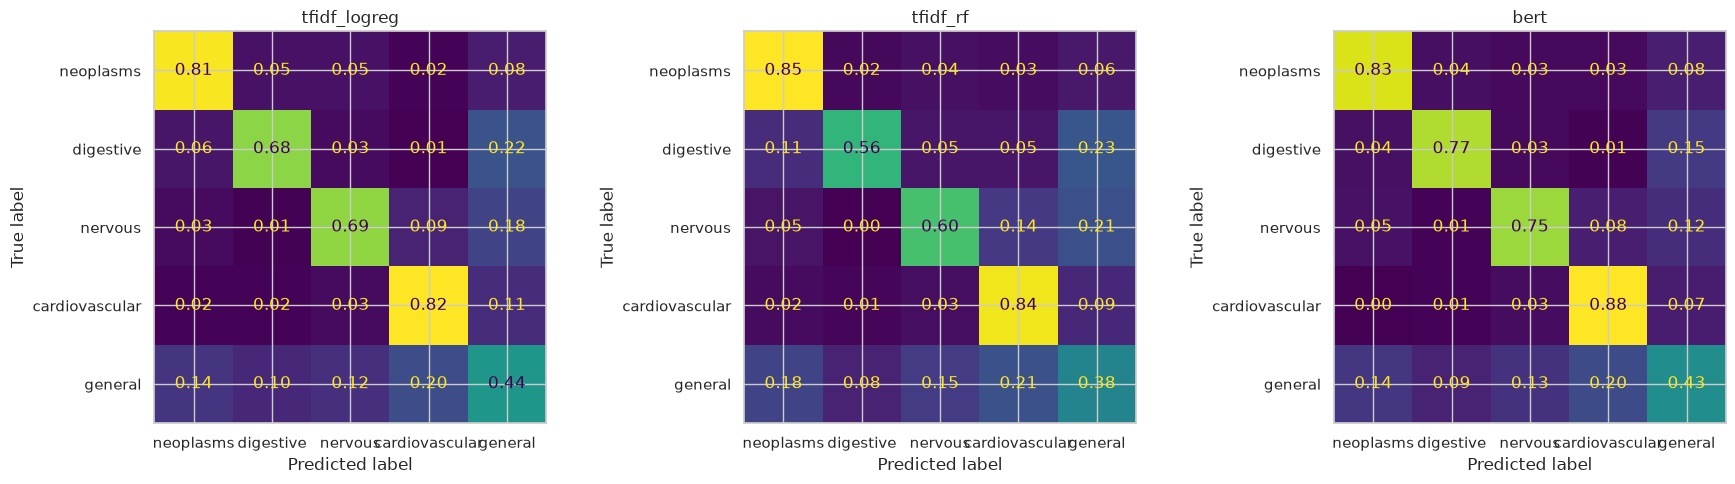

In [15]:
tabela = pd.DataFrame(comparacao).T
display(tabela.round(3))

fig, axes = plt.subplots(1, len(predicoes), figsize=(6 * len(predicoes), 5))
for ax, (nome, previsto) in zip(axes, predicoes.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_va, previsto, labels=ORDEM, normalize="true",
        display_labels=[NOMES[c].split()[0] for c in ORDEM], values_format=".2f", colorbar=False, ax=ax,
    )
    ax.set_title(nome)
plt.tight_layout()
plt.show()

## 8. Conclusões

- **Ajuste da LogReg: ganho nulo.** CV 0,657 ± 0,007 e hold-out 0,662, igual ao baseline do `01`. As 8 melhores
  combinações empatam dentro de 1 desvio-padrão. Pela regra do 1 erro-padrão, fica a 2ª colocada
  (`max_features=50k`, `C=3`): treina 2,3× mais rápido e gera um artefato menor. O TF-IDF já está no teto dele.
- **RF descartado.** Perde em tudo: F1 −4 pts (0,616), busca de 28 min, p50 de 10,6 ms (19× mais lento) e 187 MB.
- **BERT vence de forma consistente.** Na comparação pareada, ganhou nas 5 dobras, por +2,5 ± 1,0 pts
  (IC95% ≈ [+1,2; +3,8]). O hold-out sozinho sugeria +3,3, ou seja, superestimaria o ganho. Acerto por resumo:
  0,841 × 0,806.
- **O critério de aprovação não foi definido antes da execução.** A escolha do BERT é julgamento, apoiado na
  consistência entre dobras.
- **Treino é barato; o custo está em servir.** Em GPU, o fine-tuning leva 2,7 min e o F1 se estabiliza já na
  1ª época. Em CPU, sem otimização: p50 de 96 ms (~170× a LogReg) e 418 MB → motiva a etapa ONNX + INT8.
- **`max_length=256`** trunca 40% dos resumos; testes com 384 e 512 não melhoraram o F1 além do ruído e
  aumentaram a cauda de latência.
- **Limitações que continuam:**  
A classe *general* segue a mais fraca (recall 0,43).  
As latências deste notebook não são comparáveis às do `01` (máquinas diferentes).
- **Decisão:** servir o BERT (após ONNX + INT8). A LogReg fica como backend leve da API e como o modelo que a DAG
  retreina.
